In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)

print("Library berhasil di-import.")

Library berhasil di-import.


## Experiment 0 — Data Understanding & Preparation

In [2]:
# LOAD DATASET

df = pd.read_csv("UCI_Credit_Card.csv")

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


In [3]:
# MELIHAT DIMENSI DATASET

print("Jumlah observasi :", df.shape[0])
print("Jumlah variabel  :", df.shape[1])
print("Dimensi dataset  :", df.shape)

Jumlah observasi : 30000
Jumlah variabel  : 25
Dimensi dataset  : (30000, 25)


Dataset Creadit Card memiliki 30.000 observasi dan 25 variabel.

In [4]:
# MELIHAT DATA AWAL

display(df.head())

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [5]:
# 5. MELIHAT STRUKTUR DAN TIPE DATA

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

Semua kolom terisi 30.000 (non-null), tipenya numerik (13 float64, 12 int64). Tidak perlu encoding teks, dan tidak ada missing value.

In [6]:
# Melihat tipe data setiap variabel

display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str)
    })
)

,Column,Data Type
ID,ID,int64
LIMIT_BAL,LIMIT_BAL,float64
SEX,SEX,int64
EDUCATION,EDUCATION,int64
MARRIAGE,MARRIAGE,int64
AGE,AGE,int64
PAY_0,PAY_0,int64
PAY_2,PAY_2,int64
PAY_3,PAY_3,int64
PAY_4,PAY_4,int64


In [7]:
# STATISTIK DESKRIPTIF

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [8]:
# IDENTIFIKASI TARGET

target = "default.payment.next.month"

print("Target variable:", target)
print("\nNilai unik target:")
print(sorted(df[target].unique()))

Target variable: default.payment.next.month

Nilai unik target:
[np.int64(0), np.int64(1)]


Hasil identifikasi target diperoleh variabel tergetnya adalah "default.payment.next.month". Dimana 0 tidak defaul dan 1 default.


In [9]:
# 8. DISTRIBUSI TARGET

print("Jumlah masing-masing kelas:")
print(df[target].value_counts())

print("\nPersentase masing-masing kelas:")
print(df[target].value_counts(normalize=True) * 100)

Jumlah masing-masing kelas:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Persentase masing-masing kelas:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


Distribusi pada variabel target terbagi menjadi dua, yaitu label 0 atau tidak default berjumlah 13.364 dan label 1 default berjumlah 6.636.


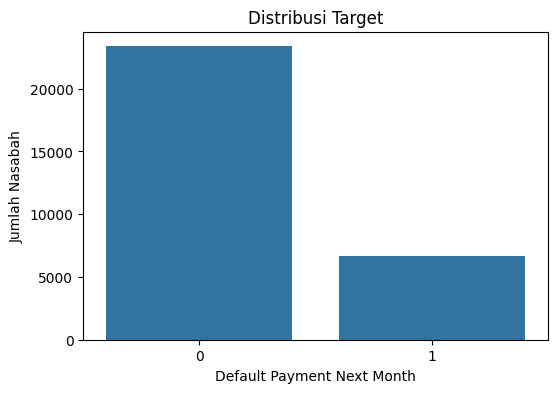

In [10]:
# Visualisasi distribusi target

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x=target)

plt.title("Distribusi Target")
plt.xlabel("Default Payment Next Month")
plt.ylabel("Jumlah Nasabah")

plt.show()

Berdasarkan bar chart diatas hasil distribusi pada default payment next month terlihat sangat tidak seimbang. Jumlah observasi tidak default jauh lebih tinggi dibandingkan observasi default.

In [11]:
# CEK MISSING VALUE

missing = df.isnull().sum()

print("Missing value setiap variabel:")
display(missing.to_frame("Missing Value"))

print("Total missing value:", missing.sum())

Missing value setiap variabel:


,Missing Value
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


Total missing value: 0


Hasil observasi menunjukkan tidak ada variabel yang memiliki nilai missing value, sehingga tidak perlu imputasi pada data.

In [12]:
# CEK DUPLICATE

duplicate_count = df.duplicated().sum()

print("Jumlah duplicate:", duplicate_count)

Jumlah duplicate: 0


Hasil diatas menunjukkan bahwa tidak ada data yang memiliki duplikasi, sehingga tidak ada data yang perlu dihapus.

In [13]:
# CEK NILAI TIDAK WAJAR / INVALID

# Variabel yang menggunakan kode kategori
categorical_columns = [
    "SEX",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

for col in categorical_columns:
    print(f"\n{'='*50}")
    print(f"Variabel: {col}")
    print(f"{'='*50}")
    print("Nilai unik:", sorted(df[col].unique()))
    print("\nJumlah masing-masing nilai:")
    print(df[col].value_counts().sort_index())


Variabel: SEX
Nilai unik: [np.int64(1), np.int64(2)]

Jumlah masing-masing nilai:
SEX
1    11888
2    18112
Name: count, dtype: int64

Variabel: EDUCATION
Nilai unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Jumlah masing-masing nilai:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

Variabel: MARRIAGE
Nilai unik: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Jumlah masing-masing nilai:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

Variabel: PAY_0
Nilai unik: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]

Jumlah masing-masing nilai:
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

Variabel: PAY_2
Nilai unik: [np.int6

In [14]:
# Nilai yang diharapkan berdasarkan struktur dataset

valid_values = {
    "SEX": [1, 2],
    "EDUCATION": [0, 1, 2, 3, 4, 5, 6],
    "MARRIAGE": [0, 1, 2, 3],
    "default.payment.next.month": [0, 1]
}

print("HASIL PEMERIKSAAN NILAI INVALID")
print("=" * 60)

for col, valid in valid_values.items():

    invalid = df.loc[~df[col].isin(valid), col]

    print(f"\n{col}")
    print("Nilai valid:", valid)
    print("Jumlah nilai invalid:", len(invalid))

    if len(invalid) > 0:
        print("Nilai invalid:")
        print(invalid.value_counts())
    else:
        print("Tidak ditemukan nilai invalid.")

HASIL PEMERIKSAAN NILAI INVALID

SEX
Nilai valid: [1, 2]
Jumlah nilai invalid: 0
Tidak ditemukan nilai invalid.

EDUCATION
Nilai valid: [0, 1, 2, 3, 4, 5, 6]
Jumlah nilai invalid: 0
Tidak ditemukan nilai invalid.

MARRIAGE
Nilai valid: [0, 1, 2, 3]
Jumlah nilai invalid: 0
Tidak ditemukan nilai invalid.

default.payment.next.month
Nilai valid: [0, 1]
Jumlah nilai invalid: 0
Tidak ditemukan nilai invalid.


Hasilnya 0 invalid untuk semua kolom. Namun perlu dicatat: daftar "valid" sudah sengaja memasukkan 0, 5, 6 (EDUCATION) dan 0 (MARRIAGE), jadi pemeriksaan ini pasti lolos. Pengecekan ini hanya memastikan tidak ada nilai di luar yang teramati, bukan memvalidasi terhadap dokumentasi.

In [15]:
# Pemeriksaan nilai PAY_0 sampai PAY_6

pay_columns = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6"
]

print("Distribusi variabel PAY")
print("=" * 60)

for col in pay_columns:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())

Distribusi variabel PAY

PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

PAY_2
PAY_2
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

PAY_3
PAY_3
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

PAY_4
PAY_4
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

PAY_5
PAY_5
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6        4
 7       58
 8        1
Name: count, dtype: int64

PAY_6
PAY_6
-2     4895
-1     5740
 0    16286
 2     2766
 3      184
 4       49
 5       13
 6       19
 7       46
 8        2


Pengulangan value_counts untuk kolom PAY saja. Tampak keanehan: nilai 1 pada PAY_2 hanya 28, PAY_3 hanya 4, PAY_4 hanya 2, dan PAY_5/PAY_6 tidak punya nilai 1 sama sekali. Pola ini tidak wajar dibanding PAY_0 (3.688 nilai 1), indikasi pencatatan data yang tidak konsisten.

In [16]:
# CEK NILAI NEGATIF

amount_columns = [
    "LIMIT_BAL",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

negative_summary = []

for col in amount_columns:
    negative_count = (df[col] < 0).sum()

    negative_summary.append({
        "Variable": col,
        "Negative Values": negative_count
    })

negative_summary = pd.DataFrame(negative_summary)

display(negative_summary)

,Variable,Negative Values
0,LIMIT_BAL,0
1,BILL_AMT1,590
2,BILL_AMT2,669
3,BILL_AMT3,655
4,BILL_AMT4,675
5,BILL_AMT5,655
6,BILL_AMT6,688
7,PAY_AMT1,0
8,PAY_AMT2,0
9,PAY_AMT3,0


LIMIT_BAL dan PAY_AMT memiliki nilai negatif namun ini wajar. Pada BILL_AMT 590-688 negatif per kolom, namun ini merupakan kredit/kelebihan bayar bukan eror sehingga tidak perlu untuk dihapus.

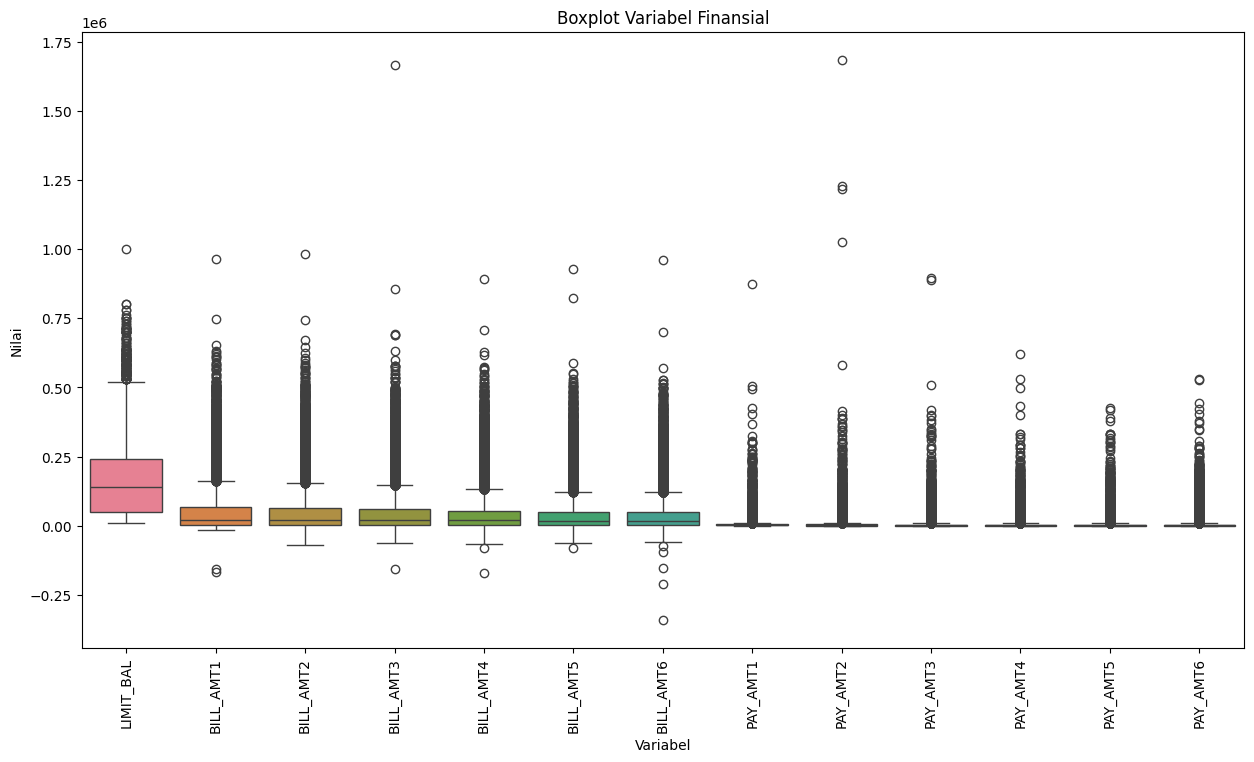

In [17]:
# CEK OUTLIER

plt.figure(figsize=(15, 8))

sns.boxplot(data=df[amount_columns])

plt.xticks(rotation=90)
plt.title("Boxplot Variabel Finansial")
plt.xlabel("Variabel")
plt.ylabel("Nilai")

plt.show()

Variabel finansial punya banyak outlier ke atas (BILL_AMT, PAY_AMT, LIMIT_BAL). Karena skalanya besar, boxplot gabungan membuat variabel kecil terlihat datar. Implikasinya: model linear sensitif, model pohon lebih tahan.

In [18]:
# MENENTUKAN PREDICTOR DAN TARGET

# ID tidak digunakan sebagai predictor
X = df.drop(columns=["ID", target])

# Target
y = df[target]

print("Jumlah predictor:", X.shape[1])
print("Nama target:", y.name)

print("\nPredictor:")
print(X.columns.tolist())

Jumlah predictor: 23
Nama target: default.payment.next.month

Predictor:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


Variabel ID tidak digunakan sebagai prediktor karena hanya identitas, sehingga variabel ID dibuang. Lalu variabel target dipisah, hasilnya variabel prediktor ada 23 variabel.

In [19]:
# TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test :", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test :", y_test.shape)

Ukuran X_train: (24000, 23)
Ukuran X_test : (6000, 23)
Ukuran y_train: (24000,)
Ukuran y_test : (6000,)


Data dibagi menjadi data training dan data testing. Dengan pembagian 80% data training dan 20% data testing. Hasilnya terdapat 24.000 data training dan 6.000 data testing. Stratify=y berfungsi menjaga proporsi kelas, sedangkan random_state=42 berfungsi menjamin hasil supaya bisa direproduksi.

In [20]:
# CEK DISTRIBUSI TARGET

distribution = pd.DataFrame({
    "Dataset": ["Original", "Training", "Testing"],
    "Class 0 (%)": [
        (y == 0).mean() * 100,
        (y_train == 0).mean() * 100,
        (y_test == 0).mean() * 100
    ],
    "Class 1 (%)": [
        (y == 1).mean() * 100,
        (y_train == 1).mean() * 100,
        (y_test == 1).mean() * 100
    ]
})

display(distribution)

,Dataset,Class 0 (%),Class 1 (%)
0,Original,77.880000,22.120000
1,Training,77.879167,22.120833
2,Testing,77.883333,22.116667


Hasil distribusi target data training dan testing tiap kelas menghasilkan masing-masing 22,12%, sehingga stratifikasi berhasil dan evaluasi adil.

## Experiment 1 — Baseline Model

In [21]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [22]:
# Membuat baseline Logistic Regression
baseline_model = LogisticRegression(
    random_state=42,
    max_iter=1000
)

baseline_model

LogisticRegression(max_iter=1000, random_state=42)

In [23]:
# 5-FOLD CROSS VALIDATION

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_f1_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("F1-score setiap fold:")
for i, score in enumerate(cv_f1_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV F1-score:", cv_f1_scores.mean())
print("Std CV F1-score :", cv_f1_scores.std())

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

F1-score setiap fold:
Fold 1: 0.4008
Fold 2: 0.3365
Fold 3: 0.3113
Fold 4: 0.3480
Fold 5: 0.3657

Mean CV F1-score: 0.3524642521329311
Std CV F1-score : 0.029941123712936935


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [24]:
# TRAINING MODEL


baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression berhasil dilatih.")

Baseline Logistic Regression berhasil dilatih.


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [25]:
# Prediksi test set
y_pred_baseline = baseline_model.predict(X_test)

In [26]:
# EVALUASI TEST SET


baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_precision = precision_score(y_test, y_pred_baseline, zero_division=0)
baseline_recall = recall_score(y_test, y_pred_baseline, zero_division=0)
baseline_f1 = f1_score(y_test, y_pred_baseline, zero_division=0)

print("=== BASELINE LOGISTIC REGRESSION ===")
print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1-score : {baseline_f1:.4f}")

=== BASELINE LOGISTIC REGRESSION ===
Accuracy : 0.8037
Precision: 0.6630
Recall   : 0.2283
F1-score : 0.3397


In [27]:
# HASIL EXPERIMENT 1


experiment_1_result = pd.DataFrame({
    "Experiment": ["Experiment 1"],
    "Model": ["Baseline Logistic Regression"],
    "CV F1": [cv_f1_scores.mean()],
    "Test Accuracy": [baseline_accuracy],
    "Test Precision": [baseline_precision],
    "Test Recall": [baseline_recall],
    "Test F1": [baseline_f1]
})

display(experiment_1_result.round(4))

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1,Baseline Logistic Regression,0.3525,0.8037,0.663,0.2283,0.3397


Hasil Experiment 1 (Baseline), model Logistic Regression tanpa preprocessing menghasilkan CV F1 sebesar 0,3525 dan Test F1 sebesar 0,3397. Akurasinya sebesar 0,8037, Recall sebesar 0,2283. Artinya model hanya mampu mendeteksi sekitar 23% nasabah yang benar-benar gagal bayar. Selain itu muncul peringatan konvergensi karena skala fitur belum disamakan.

## Experiment 2 — PREPROCESSING

In [28]:
# Logistic Regression + StandardScaler

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [29]:
# MEMBUAT PIPELINE

preprocessed_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

preprocessed_model

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [30]:
# 5-FOLD CROSS VALIDATION


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_f1_scores_exp2 = cross_val_score(
    preprocessed_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("F1-score setiap fold:")

for i, score in enumerate(cv_f1_scores_exp2, start=1):
    print(f"Fold {i}: {score:.4f}")

print("\nMean CV F1-score:", cv_f1_scores_exp2.mean())
print("Std CV F1-score :", cv_f1_scores_exp2.std())

F1-score setiap fold:
Fold 1: 0.3661
Fold 2: 0.3732
Fold 3: 0.3807
Fold 4: 0.3640
Fold 5: 0.3395

Mean CV F1-score: 0.3646986741176595
Std CV F1-score : 0.013903361986767929


In [31]:
# TRAINING MODEL


preprocessed_model.fit(X_train, y_train)

print("Logistic Regression dengan preprocessing berhasil dilatih.")

Logistic Regression dengan preprocessing berhasil dilatih.


In [32]:
# PREDIKSI TEST SET


y_pred_exp2 = preprocessed_model.predict(X_test)

In [33]:
# EVALUASI TEST SET


exp2_accuracy = accuracy_score(y_test, y_pred_exp2)

exp2_precision = precision_score(
    y_test,
    y_pred_exp2,
    zero_division=0
)

exp2_recall = recall_score(
    y_test,
    y_pred_exp2,
    zero_division=0
)

exp2_f1 = f1_score(
    y_test,
    y_pred_exp2,
    zero_division=0
)

print("=== EXPERIMENT 2 ===")
print(f"Accuracy : {exp2_accuracy:.4f}")
print(f"Precision: {exp2_precision:.4f}")
print(f"Recall   : {exp2_recall:.4f}")
print(f"F1-score : {exp2_f1:.4f}")

=== EXPERIMENT 2 ===
Accuracy : 0.8077
Precision: 0.6868
Recall   : 0.2396
F1-score : 0.3553


In [34]:
# HASIL EXPERIMENT 2

experiment_2_result = pd.DataFrame({
    "Experiment": ["Experiment 2"],
    "Model": ["Logistic Regression + StandardScaler"],
    "CV F1": [cv_f1_scores_exp2.mean()],
    "Test Accuracy": [exp2_accuracy],
    "Test Precision": [exp2_precision],
    "Test Recall": [exp2_recall],
    "Test F1": [exp2_f1]
})

display(experiment_2_result.round(4))

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 2,Logistic Regression + StandardScaler,0.3647,0.8077,0.6868,0.2396,0.3553


In [35]:
# PERBANDINGAN EXPERIMENT 1 vs EXPERIMENT 2


comparison_exp1_exp2 = pd.DataFrame({
    "Experiment": [
        "Experiment 1 - Baseline",
        "Experiment 2 - Preprocessing"
    ],
    "Model": [
        "Logistic Regression",
        "Logistic Regression + StandardScaler"
    ],
    "CV F1": [
        cv_f1_scores.mean(),
        cv_f1_scores_exp2.mean()
    ],
    "Test Accuracy": [
        baseline_accuracy,
        exp2_accuracy
    ],
    "Test Precision": [
        baseline_precision,
        exp2_precision
    ],
    "Test Recall": [
        baseline_recall,
        exp2_recall
    ],
    "Test F1": [
        baseline_f1,
        exp2_f1
    ]
})

display(comparison_exp1_exp2.round(4))

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Experiment 1 - Baseline,Logistic Regression,0.3525,0.8037,0.6630,0.2283,0.3397
1,Experiment 2 - Preprocessing,Logistic Regression + StandardScaler,0.3647,0.8077,0.6868,0.2396,0.3553


Hasil Experiment 2 (Preprocessing), setelah data diskalakan dengan StandardScaller, semua metrik mengalami kenaikan meskipun sedikit. CV F1 menjadi 0,3647, Test F1 menjadi 0,3553, precision menjadi 0,6868, dan recall menjadi 0,2396. Hasil antar fold juga lebih stabil dan peringatan konvergensi hilang. Namun peningkatan nya terbilang kecil, accuracy meningkat menjadi 0,8077 atau 80,77%.

## Experiment 3 — Model Comparison

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import pandas as pd

In [37]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(
        random_state=42,
        max_iter=1000
    ))
])

In [38]:
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [39]:
random_forest_model = RandomForestClassifier(
    random_state=42,
    n_estimators=100,
    n_jobs=-1
)

In [40]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [41]:
# LOGISTIC REGRESSION


logistic_cv_scores = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Logistic Regression")
print("=" * 40)

for i, score in enumerate(logistic_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean CV F1-score: {logistic_cv_scores.mean():.4f}")

Logistic Regression
Fold 1: 0.3661
Fold 2: 0.3732
Fold 3: 0.3807
Fold 4: 0.3640
Fold 5: 0.3395

Mean CV F1-score: 0.3647


In [42]:
logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

In [43]:
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(
    y_test, y_pred_logistic, zero_division=0
)
logistic_recall = recall_score(
    y_test, y_pred_logistic, zero_division=0
)
logistic_f1 = f1_score(
    y_test, y_pred_logistic, zero_division=0
)

print("\nTest Set:")
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1-score : {logistic_f1:.4f}")


Test Set:
Accuracy : 0.8077
Precision: 0.6868
Recall   : 0.2396
F1-score : 0.3553


In [44]:
# DECISION TREE


dt_cv_scores = cross_val_score(
    decision_tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Decision Tree")
print("=" * 40)

for i, score in enumerate(dt_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean CV F1-score: {dt_cv_scores.mean():.4f}")

Decision Tree
Fold 1: 0.4176
Fold 2: 0.4045
Fold 3: 0.4055
Fold 4: 0.3935
Fold 5: 0.3890

Mean CV F1-score: 0.4020


In [45]:
decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)

In [46]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt, zero_division=0
)

dt_recall = recall_score(
    y_test, y_pred_dt, zero_division=0
)

dt_f1 = f1_score(
    y_test, y_pred_dt, zero_division=0
)

print("\nTest Set:")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")


Test Set:
Accuracy : 0.7145
Precision: 0.3694
Recall   : 0.4115
F1-score : 0.3893


In [51]:
# RANDOM FOREST


rf_cv_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("Random Forest")
print("=" * 40)

for i, score in enumerate(rf_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean CV F1-score: {rf_cv_scores.mean():.4f}")

Random Forest
Fold 1: 0.4858
Fold 2: 0.4979
Fold 3: 0.4730
Fold 4: 0.4823
Fold 5: 0.4648

Mean CV F1-score: 0.4808


In [52]:
random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)

In [53]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf, zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf, zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf, zero_division=0
)

print("\nTest Set:")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-score : {rf_f1:.4f}")


Test Set:
Accuracy : 0.8120
Precision: 0.6325
Recall   : 0.3580
F1-score : 0.4572


In [54]:
# PERBANDINGAN MODEL


experiment_3_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "CV F1": [
        logistic_cv_scores.mean(),
        dt_cv_scores.mean(),
        rf_cv_scores.mean()
    ],

    "Test Accuracy": [
        logistic_accuracy,
        dt_accuracy,
        rf_accuracy
    ],

    "Test Precision": [
        logistic_precision,
        dt_precision,
        rf_precision
    ],

    "Test Recall": [
        logistic_recall,
        dt_recall,
        rf_recall
    ],

    "Test F1": [
        logistic_f1,
        dt_f1,
        rf_f1
    ]
})

display(experiment_3_results.round(4))

,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Logistic Regression,0.3647,0.8077,0.6868,0.2396,0.3553
1,Decision Tree,0.4020,0.7145,0.3694,0.4115,0.3893
2,Random Forest,0.4808,0.8120,0.6325,0.3580,0.4572


In [55]:
# MENENTUKAN MODEL TERBAIK


best_model_row = experiment_3_results.loc[
    experiment_3_results["CV F1"].idxmax()
]

print("Model terbaik berdasarkan CV F1-score:")
print(best_model_row["Model"])

print(f"\nCV F1-score      : {best_model_row['CV F1']:.4f}")
print(f"Test Accuracy    : {best_model_row['Test Accuracy']:.4f}")
print(f"Test Precision   : {best_model_row['Test Precision']:.4f}")
print(f"Test Recall      : {best_model_row['Test Recall']:.4f}")
print(f"Test F1-score    : {best_model_row['Test F1']:.4f}")

Model terbaik berdasarkan CV F1-score:
Random Forest

CV F1-score      : 0.4808
Test Accuracy    : 0.8120
Test Precision   : 0.6325
Test Recall      : 0.3580
Test F1-score    : 0.4572


Hasil Experiment 3 (Perbandingan Model), Tiga model dibandingkan, yaitu Logistic Regression, Decision Tree, dan Random Forest. Random Forest memiliki hasil evalasi terbaik dengan CV F1 sebesar 0,4808, Test F1 0,4572, dan akurasinya sebesar 0,8120. Decission Tree memiliki recall tertinggi sebesar 0,4115, tetapi precisionnya rendah sebesar 0,3694 dan akurasinya turun ke 0,7145 yang menandakan model terlalu agresif dan cenderung overfitting. Logistic Regression punya precision tinggi tetapi recall paling rendah. Random Forest memberi keseimbangan terbaik karena menggabungkan banyak pohon sehingga lebih stabil dan mampu menangkap pola non-linear.

## Experiment 4 — Hyperparameter Tuning

In [62]:
# RANDOM FOREST

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

In [63]:
# MODEL RANDOM FOREST

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)


In [64]:
# HYPERPARAMETER YANG DIUJI

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
}

In [65]:
# STRATIFIED 5-FOLD CROSS VALIDATION


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)



In [67]:
# GRID SEARCH

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)


Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'min_samples_split': [2, 5],
                         'n_estimators': [100, 200]},
             scoring='f1', verbose=1)

In [68]:
# HASIL HYPERPARAMETER TERBAIK


print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:")
print(f"{grid_search.best_score_:.4f}")

Best Parameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}

Best CV F1-score:
0.4808


In [69]:
# Model terbaik
best_rf_model = grid_search.best_estimator_

# Prediksi test set
best_rf_pred = best_rf_model.predict(X_test)

In [70]:
# Test Set Evaluation
tuned_accuracy = accuracy_score(y_test, best_rf_pred)
tuned_precision = precision_score(y_test, best_rf_pred, zero_division=0)
tuned_recall = recall_score(y_test, best_rf_pred, zero_division=0)
tuned_f1 = f1_score(y_test, best_rf_pred, zero_division=0)


print("\nTest Set Performance:")
print(f"Test Accuracy  : {tuned_accuracy:.4f}")
print(f"Test Precision : {tuned_precision:.4f}")
print(f"Test Recall    : {tuned_recall:.4f}")
print(f"Test F1-score  : {tuned_f1:.4f}")


Test Set Performance:
Test Accuracy  : 0.8120
Test Precision : 0.6325
Test Recall    : 0.3580
Test F1-score  : 0.4572


In [71]:
# PERBANDINGAN SEBELUM VS SETELAH TUNING


comparison_exp4 = pd.DataFrame({
    "Metric": [
        "CV F1-score",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1-score"
    ],

    "Before Tuning": [
        0.4808,
        0.8120,
        0.6325,
        0.3580,
        0.4572
    ],

    "After Tuning": [
        grid_search.best_score_,
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1
    ]
})

# Menghitung perubahan performa
comparison_exp4["Improvement"] = (
    comparison_exp4["After Tuning"]
    - comparison_exp4["Before Tuning"]
)

# Tampilkan hasil
comparison_exp4.round(4)

,Metric,Before Tuning,After Tuning,Improvement
0,CV F1-score,0.4808,0.4808,-0.0
1,Test Accuracy,0.8120,0.8120,0.0
2,Test Precision,0.6325,0.6325,-0.0
3,Test Recall,0.3580,0.3580,-0.0
4,Test F1-score,0.4572,0.4572,-0.0


Hasil Experiment 4 (Hyperparameter Tuning), Grid research pada Random Forest memiliki parameter n_estimators=100, max=depth=None, dan min_samples_split=2, yang sama dengan pengaturan default. Akibatnya, hasil sebelum dan sesuadah tuning identik (CV F1 0,4808, Test F1 0,4572). Hal ini berarti tuning tidak meningkatkan performa, dan untuk kombinasi parameter yang diuji, pengaturan default sudah yang terbaik. Peningkatan mungkin bisa dicapai dengan menguji parameter lain atau memperluas rentang pencarian.

## Experiment 5 — Advanced Model

In [75]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

In [76]:
gradient_boosting_model = GradientBoostingClassifier(
    random_state=42
)

In [77]:
# STRATIFIED 5-FOLD CROSS VALIDATION

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [78]:
# CROSS VALIDATION

gb_cv_scores = cross_val_score(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="f1"
)

print("CV F1-score setiap fold:")
print(gb_cv_scores)

print("\nMean CV F1-score:")
print(f"{gb_cv_scores.mean():.4f}")

CV F1-score setiap fold:
[0.47467968 0.48951911 0.47387606 0.48492159 0.47001224]

Mean CV F1-score:
0.4786


In [79]:
# TRAINING MODEL

gradient_boosting_model.fit(
    X_train,
    y_train
)

GradientBoostingClassifier(random_state=42)

In [80]:
# PREDIKSI TEST SET

gb_pred = gradient_boosting_model.predict(X_test)

In [81]:
# EVALUASI

gb_accuracy = accuracy_score(
    y_test,
    gb_pred
)

gb_precision = precision_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    gb_pred,
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    gb_pred,
    zero_division=0
)

In [82]:
# HASIL EXPERIMENT 5

experiment_5_result = pd.DataFrame({
    "Model": ["Gradient Boosting"],
    "CV F1": [gb_cv_scores.mean()],
    "Test Accuracy": [gb_accuracy],
    "Test Precision": [gb_precision],
    "Test Recall": [gb_recall],
    "Test F1": [gb_f1]
})

experiment_5_result.round(4)

,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Gradient Boosting,0.4786,0.8183,0.6634,0.3625,0.4688


Hasil Experiment 5 (Advanced Model), Gradient Boosting menghasilkan CV F1 0,4786 dan Test F1 0,4688, dengan accuracy 0,8183, precision 0,6634, dan recall 0,3625. Pada data uji, model ini sedikit lebih baik dari Random Forest di semua metrik, sedangkan pada CV F1 Random Forest sedikit lebih tinggi. Selisih keduanya sangat kecil sehingga performanya hampir setara. Secara keseluruhan, pergantian dari model linear ke model ensemble memberi peningkatan terbesar, sedangkan recall semua model masih rendah (sekitar 36% pada model terbaik) karena data yang tidak seimbang.

In [84]:
# PERBANDINGAN EXPERIMENT 4 VS EXPERIMENT 5


# 1. RANDOM FOREST TERBAIK DARI EXPERIMENT 4


best_rf_model = grid_search.best_estimator_

rf_test_pred = best_rf_model.predict(X_test)

rf_accuracy = accuracy_score(
    y_test,
    rf_test_pred
)

rf_precision = precision_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_recall = recall_score(
    y_test,
    rf_test_pred,
    zero_division=0
)

rf_f1 = f1_score(
    y_test,
    rf_test_pred,
    zero_division=0
)



# 2. GRADIENT BOOSTING DARI EXPERIMENT 5

gb_test_pred = gradient_boosting_model.predict(X_test)

gb_accuracy = accuracy_score(
    y_test,
    gb_test_pred
)

gb_precision = precision_score(
    y_test,
    gb_test_pred,
    zero_division=0
)

gb_recall = recall_score(
    y_test,
    gb_test_pred,
    zero_division=0
)

gb_f1 = f1_score(
    y_test,
    gb_test_pred,
    zero_division=0
)


# 3. TABEL PERBANDINGAN


comparison_exp5 = pd.DataFrame({
    "Metric": [
        "CV F1-score",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1-score"
    ],

    "Random Forest (Exp 4)": [
        grid_search.best_score_,
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ],

    "Gradient Boosting (Exp 5)": [
        gb_cv_scores.mean(),
        gb_accuracy,
        gb_precision,
        gb_recall,
        gb_f1
    ]
})

comparison_exp5.round(4)

,Metric,Random Forest (Exp 4),Gradient Boosting (Exp 5)
0,CV F1-score,0.4808,0.4786
1,Test Accuracy,0.8120,0.8183
2,Test Precision,0.6325,0.6634
3,Test Recall,0.3580,0.3625
4,Test F1-score,0.4572,0.4688


In [86]:
# SUMMARY HASIL EXPERIMENT 1 - 5

summary_results = pd.DataFrame({
    "Experiment": [
        "1",
        "2",
        "3",
        "4",
        "5"
    ],

    "Model": [
        "Baseline Logistic Regression",
        "Logistic Regression + Preprocessing",
        "Random Forest",
        "Tuned Random Forest",
        "Gradient Boosting"
    ],

    "CV F1": [
        cv_f1_scores.mean(),
        cv_f1_scores_exp2.mean(),
        rf_cv_scores.mean(),
        grid_search.best_score_,
        gb_cv_scores.mean()
    ],

    "Test Accuracy": [
        baseline_accuracy,
        exp2_accuracy,
        rf_accuracy,
        rf_accuracy,
        gb_accuracy
    ],

    "Test Precision": [
        baseline_precision,
        exp2_precision,
        rf_precision,
        rf_precision,
        gb_precision
    ],

    "Test Recall": [
        baseline_recall,
        exp2_recall,
        rf_recall,
        rf_recall,
        gb_recall
    ],

    "Test F1": [
        baseline_f1,
        exp2_f1,
        rf_f1,
        rf_f1,
        gb_f1
    ]
})

summary_results.round(4)

,Experiment,Model,CV F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,1,Baseline Logistic Regression,0.3525,0.8037,0.6630,0.2283,0.3397
1,2,Logistic Regression + Preprocessing,0.3647,0.8077,0.6868,0.2396,0.3553
2,3,Random Forest,0.4808,0.8120,0.6325,0.3580,0.4572
3,4,Tuned Random Forest,0.4808,0.8120,0.6325,0.3580,0.4572
4,5,Gradient Boosting,0.4786,0.8183,0.6634,0.3625,0.4688


Dari lima eksperimen, hasil menunjukkan bahwa jenis model sangat berpengaruh terhadap performa model. Preprocessing dengan StandardScaler hanya menaikkan F1-score sedikit dari yang awalnya 0,3397 menjadi 0,3553 pada test set. Perpindahan dari Logistic Regression ke model berbasis pohon seperti Random Forest memberikan peningkatan jauh lebih besar. Hyperparameter Tuning tidak menambah performa karena parameter terbaik yang diperoleh sama dengan model default. Gradient Boosting pada Experiment 5 memberikan hasil sedikit lebih baik pada data uji. Secara keseluruhan, model ensemble jauh lebih baik daripada model linear, tetapi recall semua model masih terbilang cukup rendah sekitar 36% pada model terbaik. Hal ini terjadi dikarenakan data target yang tidak seimbang antar kelas, sehingga masih banyak nasabah gagal bayar yang belum terdeteksi.